In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import os
os.getcwd()

'C:\\Users\\SRUTHI\\OneDrive\\Desktop\\Weekly task'

In [3]:
df = pd.read_csv(r"C:\\Users\\SRUTHI\\OneDrive\\Desktop\\Weekly task\hotel_bookings.csv")
print("Dataset loaded successfully")

Dataset loaded successfully


In [4]:
print(df.head())

          hotel  is_canceled  lead_time  arrival_date_year arrival_date_month  \
0  Resort Hotel            0        342               2015               July   
1  Resort Hotel            0        737               2015               July   
2  Resort Hotel            0          7               2015               July   
3  Resort Hotel            0         13               2015               July   
4  Resort Hotel            0         14               2015               July   

   arrival_date_week_number  arrival_date_day_of_month  \
0                        27                          1   
1                        27                          1   
2                        27                          1   
3                        27                          1   
4                        27                          1   

   stays_in_weekend_nights  stays_in_week_nights  adults  ...  deposit_type  \
0                        0                     0       2  ...    No Deposit   
1     

In [5]:
print("Dataset Shape:", df.shape)

Dataset Shape: (119390, 32)


In [6]:
print(df.columns)

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='object')


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [8]:
print(df.isnull().sum())

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [9]:
print(df.describe())


         is_canceled      lead_time  arrival_date_year  \
count  119390.000000  119390.000000      119390.000000   
mean        0.370416     104.011416        2016.156554   
std         0.482918     106.863097           0.707476   
min         0.000000       0.000000        2015.000000   
25%         0.000000      18.000000        2016.000000   
50%         0.000000      69.000000        2016.000000   
75%         1.000000     160.000000        2017.000000   
max         1.000000     737.000000        2017.000000   

       arrival_date_week_number  arrival_date_day_of_month  \
count             119390.000000              119390.000000   
mean                  27.165173                  15.798241   
std                   13.605138                   8.780829   
min                    1.000000                   1.000000   
25%                   16.000000                   8.000000   
50%                   28.000000                  16.000000   
75%                   38.000000            

In [10]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 31994


In [11]:
print(df["hotel"].value_counts())

hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64


In [12]:
print("Cancellation Rate (%):",
      df["is_canceled"].mean() * 100)

Cancellation Rate (%): 37.041628277075134


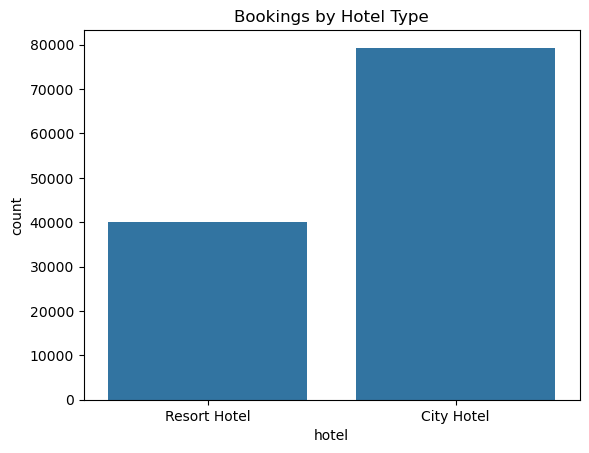

In [13]:
sns.countplot(data=df, x="hotel")
plt.title("Bookings by Hotel Type")
plt.show()

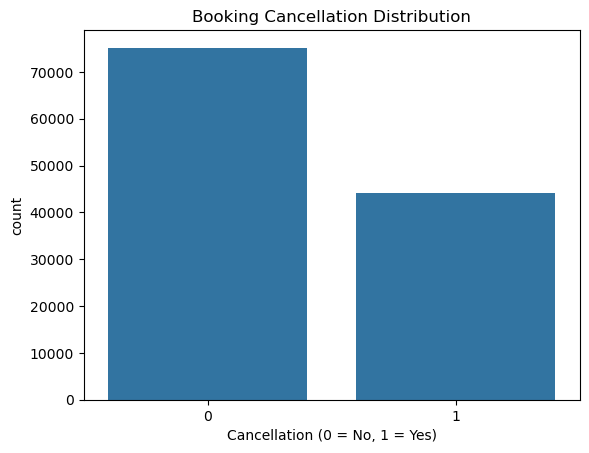

In [14]:
sns.countplot(data=df, x="is_canceled")
plt.title("Booking Cancellation Distribution")
plt.xlabel("Cancellation (0 = No, 1 = Yes)")
plt.show()

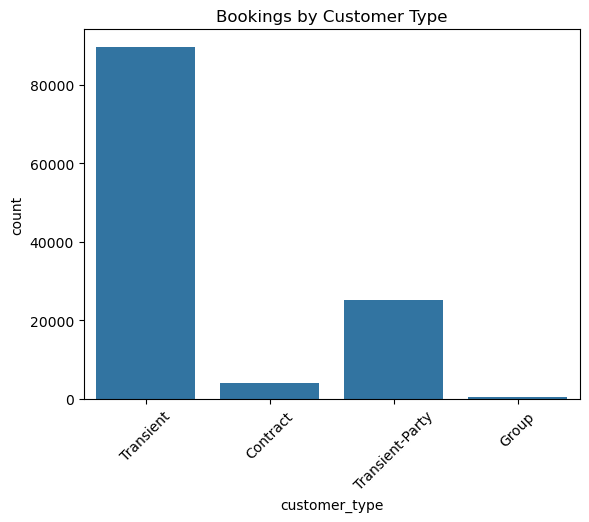

In [15]:
sns.countplot(data=df, x="customer_type")
plt.title("Bookings by Customer Type")
plt.xticks(rotation=45)
plt.show()

In [16]:
print("Average Daily Rate:", df["adr"].mean())

Average Daily Rate: 101.83112153446687


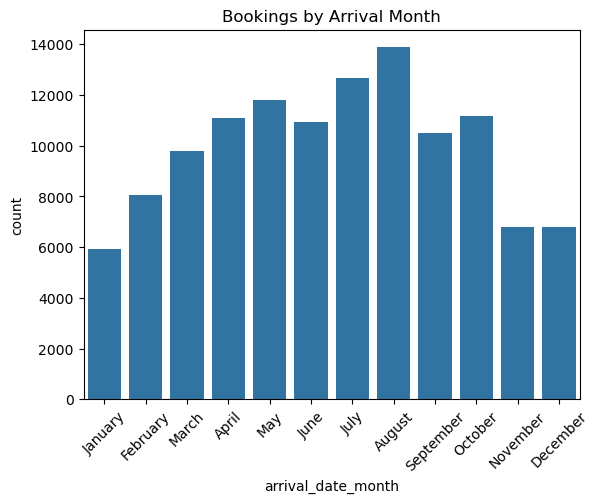

In [17]:
sns.countplot(
    data=df,
    x="arrival_date_month",
    order=[
        "January", "February", "March", "April",
        "May", "June", "July", "August",
        "September", "October", "November", "December"
    ]
)
plt.title("Bookings by Arrival Month")
plt.xticks(rotation=45)
plt.show()

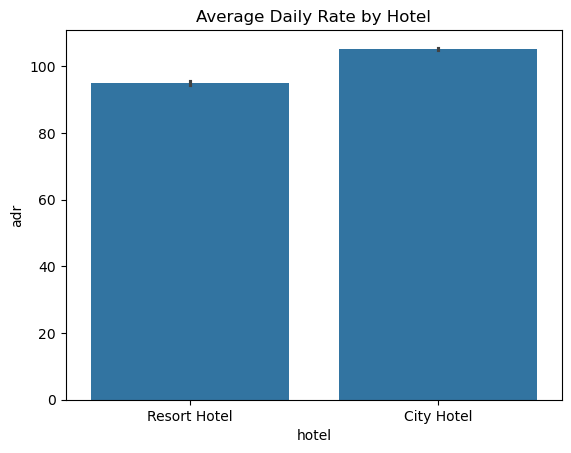

In [18]:
sns.barplot(data=df, x="hotel", y="adr")
plt.title("Average Daily Rate by Hotel")
plt.show()

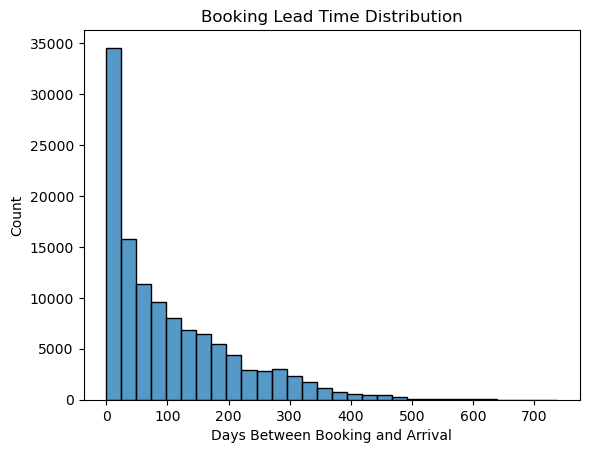

In [19]:
sns.histplot(data=df, x="lead_time", bins=30)
plt.title("Booking Lead Time Distribution")
plt.xlabel("Days Between Booking and Arrival")
plt.show()

In [20]:
df["total_nights"] = (
    df["stays_in_weekend_nights"] +
    df["stays_in_week_nights"]
)

print(df["total_nights"].describe())

count    119390.000000
mean          3.427900
std           2.557439
min           0.000000
25%           2.000000
50%           3.000000
75%           4.000000
max          69.000000
Name: total_nights, dtype: float64


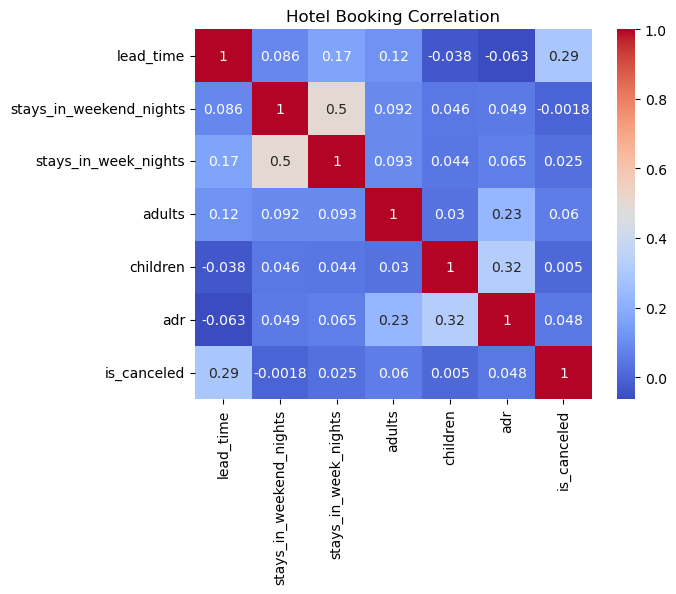

In [21]:
cols = [
    "lead_time", "stays_in_weekend_nights",
    "stays_in_week_nights", "adults",
    "children", "adr", "is_canceled"
]

sns.heatmap(
    df[cols].corr(),
    annot=True,
    cmap="coolwarm"
)
plt.title("Hotel Booking Correlation")
plt.show()